# 01 · Baseline StyleSync IA - Garments2Look y CatVTON

Baseline para validar el pipeline de extremo a extremo con datos reales. Este notebook caracteriza Garments2Look mediante metadatos descargados con hf_hub_download y muestreo por streaming de polyvore/looks-resized.tar.gz (n=200) sin persistir los 284 GB, extrae pose con MediaPipe y DWPose, y ejecuta CatVTON sobre una prenda y en secuencia de tres con registro en MLflow.

Fuera de alcance: ajuste fino del modelo de difusion, multi-reference avanzado, single-pass de seis prendas, integraciones VLM/CLIP, segmentacion pesada, tiempo real, AR y backend (FastAPI, Redis, Next.js). La adaptación multi-prenda con layering corresponde a los notebooks 03 y 04.


## 1. Configuración del entorno

Verifica el hardware disponible (CUDA, GPU y VRAM) antes de ejecutar pasos con mayor costo. El resultado queda registrado como evidencia del entorno.

In [1]:
import sys, platform, subprocess
from pathlib import Path

# Detección de entorno (Colab vs local): usado en todo el notebook
IS_COLAB = Path("/content").exists()
REPO_ROOT = Path("/content/MACHINE-BULLS") if IS_COLAB and Path("/content/MACHINE-BULLS").exists() else (Path("/content") if IS_COLAB else Path.cwd().resolve())
if not IS_COLAB:
    for parent in [REPO_ROOT] + list(REPO_ROOT.parents):
        if (parent / "notebooks" / "01_baseline_stylesync_garments2look.ipynb").exists():
            REPO_ROOT = parent
            break
    if (REPO_ROOT / "MACHINE-BULLS" / "notebooks").exists():
        REPO_ROOT = REPO_ROOT / "MACHINE-BULLS"
# Si es Colab, montar Drive y copiar A-Pose desde MyDrive/MACHINE-BULLS/sample_data
if IS_COLAB:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        import shutil
        src = Path("/content/drive/MyDrive/MACHINE-BULLS/sample_data/usuario_apose.jpg")
        dst = REPO_ROOT / "sample_data/usuario_apose.jpg"
        dst.parent.mkdir(parents=True, exist_ok=True)
        if src.exists():
            shutil.copy(str(src), str(dst))
            print(f"Imagen copiada Drive -> {dst} ({dst.stat().st_size/1024:.1f} KB)")
        else:
            print(f"[WARN] No se encontro {src}, usando repo local si existe")
            if dst.exists():
                print(f"Usando existente {dst}")
    except Exception as e:
        print(f"[WARN] Drive mount fallo: {e}")
print(f"Entorno: {'Colab' if IS_COLAB else 'Local'} | Repo root: {REPO_ROOT} | Python: {sys.version.split()[0]}")
print(f"Plataforma: {platform.platform()}")

try:
    import torch
    print(f"PyTorch: {torch.__version__}")
    print(f"CUDA disponible: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        idx = torch.cuda.current_device()
        props = torch.cuda.get_device_properties(idx)
        vram_gb = props.total_memory / (1024 ** 3)
        print(f"GPU detectada: {torch.cuda.get_device_name(idx)}")
        print(f"VRAM total: {vram_gb:.2f} GB")
        print(f"Capability: {props.major}.{props.minor}")
    else:
        print("[WARN] No se detecto GPU. CatVTON requiere GPU con >= 12 GB VRAM.")
except ImportError:
    print("PyTorch no instalado (ver Sección 2).")


Entorno: Local | Repo root: E:\MACHINEBULLS\MACHINE-BULLS | Python: 3.11.9
Plataforma: Windows-10-10.0.26200-SP0
PyTorch: 2.6.0+cu124
CUDA disponible: True
GPU detectada: NVIDIA GeForce RTX 4070 Laptop GPU
VRAM total: 8.00 GB
Capability: 8.9


## 1b. Configuracion de MLflow Tracking

Tracking remoto en https://humorous-trusting-domelike.ngrok-free.dev, expuesto por backend/scripts/mlflow_ngrok.py. Experiment: 01-baseline-garments2look. Las metricas de sistema se habilitan cuando hay GPU disponible.


In [2]:
%pip install -q "mlflow==3.16.1" "mediapipe==1.0.1" av lpips "controlnet-aux==0.0.10" fvcore 


Note: you may need to restart the kernel to use updated packages.


In [3]:
# ---- Higiene de salidas: silencia warnings conocidos de librerias ----
# Filtros angostos (módulo+mensaje): los errores reales siguen visibles.
import warnings

warnings.filterwarnings("ignore", message="Flax classes are deprecated", module="diffusers")
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks", module="huggingface_hub")
warnings.filterwarnings("ignore", message=".*pass the indexing argument")
warnings.filterwarnings("ignore", message="The parameter .pretrained. is deprecated", module="torchvision")
warnings.filterwarnings("ignore", message="Arguments other than a weight enum", module="torchvision")

# Barras de progreso y verbosidad de librerias (ruido visual, no errores)
import os
os.environ["HF_HUB_VERBOSITY"] = "error"
try:
    from diffusers.utils import logging as diffusers_logging
    diffusers_logging.set_verbosity_error()
except Exception:
    pass
try:
    from transformers.utils import logging as transformers_logging
    transformers_logging.set_verbosity_error()
except Exception:
    pass
print("[OK] Higiene de salidas aplicada (warnings conocidos silenciados)")


e:\MACHINEBULLS\MACHINE-BULLS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Higiene de salidas aplicada (warnings conocidos silenciados)


In [4]:
import mlflow
REMOTE_URI = "https://humorous-trusting-domelike.ngrok-free.dev"
try:
    mlflow.set_tracking_uri(REMOTE_URI)
    mlflow.set_experiment("01-baseline-garments2look")
    print(f"[OK] MLflow remoto: {REMOTE_URI}")
except Exception as e:
    print(f"[WARN] MLflow remoto no levantado ({e})")
    print(f"   Levanta local: uv run python backend/scripts/mlflow_ngrok.py")
mlflow.config.enable_system_metrics_logging()
mlflow.config.set_system_metrics_sampling_interval(10)


[WARN] MLflow remoto no levantado (API request to endpoint /api/2.0/mlflow/experiments/get-by-name failed with error code 404 != 200. Response body: '<!DOCTYPE html>
<html class="h-full" lang="en-US" dir="ltr">
  <head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-Regular-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-RegularItalic-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-Medium-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-MediumItalic-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" hr

## 2. Dependencias

Instala solo lo necesario para EDA, preprocesamiento de pose y el baseline CatVTON. Ejecutar una vez y luego comentar la celda si el entorno ya cuenta con las librerías.

In [5]:
# Dependencias ya instaladas en la celda 4 con %pip (mlflow, mediapipe, fvcore, etc.).
# Esta celda queda como referencia comentada para entorno limpio. No reinstala torch para no romper el runtime de Colab.

# EDA y utilidades generales
# !pip install -q huggingface_hub pandas numpy matplotlib seaborn pillow tqdm

# Métricas de imagen
# !pip install -q scikit-image lpips

# Vision computacional / pose
# !pip install -q mediapipe opencv-python-headless

# Stack de inferencia VTON (CatVTON usa diffusers + torch)
# !pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu121
# !pip install -q diffusers transformers accelerate safetensors

# Repositorio de CatVTON (contiene model.pipeline.CatVTONPipeline y model.cloth_masker.AutoMasker).
# !git clone https://github.com/Zheng-Chong/CatVTON.git

# DWPose
# !pip install -q controlnet-aux


## 3. Carga del dataset Garments2Look (solo metadatos)

Hugging Face ya no soporta scripts de carga `.py` como `Garments2Look.py`, por lo que
`datasets.load_dataset("ArtmeScienceLab/Garments2Look", streaming=True)`
falla con `RuntimeError: Dataset scripts are no longer supported`.

En su lugar se descargan solo los archivos de metadatos con `hf_hub_download`, que pesan algunos MB en lugar de los 284 GB del dataset completo:

- `*_outfit_v1.0_2512.json`: un outfit por entrada con forma `dict {outfit_id: {source, gender, outfit_info, section, is_official_outfit, is_official_look, outfit}}`, donde `outfit` es `dict {garment_id: descripción corta}`. No es una lista y no incluye la clave `garments`.
- `*_image_v1.0_2512.json`: catálogo de prendas `dict {garment_id: {source, gender, type, name, images, color, features, official_description, description, main_category}}`. Aquí se encuentran la categoría `type` con formato `clothing::tops::short-sleeved tops` y las rutas de imagen en `images.product.full`.

Algunos `garment_id` con prefijo `UM...` no aparecen en el catálogo de imágenes y se tratan como "sin catálogo" para no interrumpir el cruce.

In [6]:
from huggingface_hub import hf_hub_download
import json

REPO_ID = "ArtmeScienceLab/Garments2Look"
REPO_TYPE = "dataset"

OUTFIT_METADATA_FILES = [
    "mytheresa_outfit_v1.0_2512.json",
    "polyvore_outfit_v1.0_2512.json",
]

outfit_metadata_paths = {}

for fname in OUTFIT_METADATA_FILES:
    try:
        path = hf_hub_download(
            repo_id=REPO_ID,
            filename=fname,
            repo_type=REPO_TYPE
        )

        outfit_metadata_paths[fname] = path

        print(f"[OK] Descargado: {fname}")
        print(f"     Ruta local/cache: {path}")

    except Exception as e:
        print(f"[WARN] No se pudo descargar {fname}: {type(e).__name__}: {e}")


# ============================================================
# Normalizar los JSON
# ============================================================

raw_outfits = []

for fname, path in outfit_metadata_paths.items():

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    if isinstance(data, dict):

        outfits_lista = []

        for outfit_id, outfit_data in data.items():

            outfit_norm = dict(outfit_data)
            outfit_norm["outfit_id"] = outfit_id

            outfits_lista.append(outfit_norm)

    elif isinstance(data, list):

        outfits_lista = data

    else:

        outfits_lista = []

    print(f"[OK] {fname}: {len(outfits_lista)} outfits cargados")

    raw_outfits.extend(outfits_lista)


print(f"\n[OK] Total de outfits combinados en memoria: {len(raw_outfits)}")

[OK] Descargado: mytheresa_outfit_v1.0_2512.json
     Ruta local/cache: C:\Users\mfjm0\.cache\huggingface\hub\datasets--ArtmeScienceLab--Garments2Look\snapshots\5324b92e86beefa27196116c6d3957fcc6242205\mytheresa_outfit_v1.0_2512.json
[OK] Descargado: polyvore_outfit_v1.0_2512.json
     Ruta local/cache: C:\Users\mfjm0\.cache\huggingface\hub\datasets--ArtmeScienceLab--Garments2Look\snapshots\5324b92e86beefa27196116c6d3957fcc6242205\polyvore_outfit_v1.0_2512.json
[OK] mytheresa_outfit_v1.0_2512.json: 61955 outfits cargados
[OK] polyvore_outfit_v1.0_2512.json: 18086 outfits cargados

[OK] Total de outfits combinados en memoria: 80041


In [7]:
# Fallback heredado solo si el repo es inaccesible (sin token). Con datos reales no se ejecuta.
import random

def _make_synthetic_outfits(n=500, seed=42):
    random.seed(seed)
    categorias = [
        "clothing::tops::t-shirt", "clothing::bottom::pants", "clothing::bottom::jeans",
        "clothing::outerwear::jacket", "clothing::outerwear::coat", "clothing::dress",
        "shoes::sneakers", "shoes::boots", "accessory::bag", "accessory::hat",
        "accessory::belt", "clothing::sweater", "clothing::bottom::shorts",
    ]
    outfits = []
    for i in range(n):
        n_garments = random.choices(population=list(range(3, 13)), weights=[18, 22, 20, 14, 10, 7, 4, 2, 1.5, 0.5], k=1)[0]
        outfit_dict = {f"SYN{i:05d}{j:02d}": f"prenda sintetica {random.choice(categorias)}" for j in range(n_garments)}
        outfits.append({"outfit_id": f"outfit_{i:05d}_d2", "source": "sintetico", "gender": random.choice(["women", "men"]), "outfit_info": {"style": "N/A", "season": "N/A"}, "outfit": outfit_dict})
    return outfits

if len(raw_outfits) == 0:
    raise RuntimeError("No se cargaron outfits reales y el fallback sintetico esta desactivado para honestidad. Verifica el token de Hugging Face y el acceso al dataset.")

print(f"Outfits disponibles para el EDA: {len(raw_outfits)}")


Outfits disponibles para el EDA: 80041


In [8]:
# Catálogo de prendas (categoría, color, rutas de imagen), indexado por
# garment_id. Se fusionan las dos fuentes (mytheresa + polyvore) en un
# único diccionario.
IMAGE_METADATA_FILES = [
    "mytheresa_image_v1.0_2512.json",
    "polyvore_image_v1.0_2512.json",
]

garment_catalog = {}  # garment_id -> metadata de la prenda

for fname in IMAGE_METADATA_FILES:
    try:
        path = hf_hub_download(repo_id=REPO_ID, filename=fname, repo_type=REPO_TYPE)
    except Exception as e:
        print(f"[WARN] No se pudo descargar {fname}: {e}")
        continue

    with open(path, "r", encoding="utf-8") as f:
        catalogo = json.load(f)

    print(f"{fname}: {len(catalogo)} prendas catalogadas")
    garment_catalog.update(catalogo)

print(f"\nTotal de prendas en el catálogo combinado: {len(garment_catalog)}")

mytheresa_image_v1.0_2512.json: 62457 prendas catalogadas
polyvore_image_v1.0_2512.json: 126928 prendas catalogadas

Total de prendas en el catálogo combinado: 189385


## 4. Exploración de metadatos

Esta sección revisa la jerarquía de un outfit. outfit_info describe estilo, temporada, ocasión y paleta. outfit es dict {garment_id: descripción corta}. Los identificadores se cruzan con el catálogo para obtener categoría, color y nombre.

Resuelto: las imágenes de look están en polyvore/looks-resized.tar.gz y se leen por streaming en la sección 6.


In [9]:
outfit0 = raw_outfits[0]

print("Campos del outfit:", list(outfit0.keys()))
print("\noutfit_id:", outfit0.get("outfit_id"))
print("source:", outfit0.get("source"), "| gender:", outfit0.get("gender"))
print("nº de prendas en este outfit:", len(outfit0.get("outfit", {})))

info = outfit0.get("outfit_info", {})
print("\noutfit_info -> style:", info.get("style"), "| season:", info.get("season"),
      "| occasion:", info.get("occasion"))

print("\nPrendas del outfit (garment_id · descripción · categoría si está catalogada):")
for garment_id, descripcion in outfit0.get("outfit", {}).items():
    catalogado = garment_catalog.get(garment_id)
    if catalogado:
        print(f" - {garment_id}: {descripcion}  ->  type={catalogado.get('type')}, "
              f"color={catalogado.get('color')}")
    else:
        print(f" - {garment_id}: {descripcion}  ->  (sin entrada en el catálogo)")

Campos del outfit: ['source', 'gender', 'outfit_info', 'section', 'is_official_outfit', 'is_official_look', 'outfit', 'outfit_id']

outfit_id: P00590931_d2
source: mytheresa | gender: women
nº de prendas en este outfit: 6

outfit_info -> style: Contemporary Casual | season: Summer | occasion: Daily Wear, Casual Outing

Prendas del outfit (garment_id · descripción · categoría si está catalogada):
 - P00831132: white knot cotton jersey t-shirt  ->  type=clothing::tops::short-sleeved tops, color=white
 - P01021174: black wool gabardine shorts  ->  type=clothing::shorts::tailored, color=black
 - P00590931: white leather sneakers  ->  type=shoes::sneakers::low-top sneakers, color=white
 - UM00000002: black leather handbag  ->  (sin entrada en el catálogo)
 - P00760957: gold clip-on earrings  ->  type=jewelry::fashion jewelry::earrings, color=gold
 - UM00000001: black leather belt with gold buckle  ->  (sin entrada en el catálogo)


## 5. EDA nivel 1: estructura de metadatos y estadisticas

n_garments cuenta las claves de outfit["outfit"]. El resultado se compara con la media documentada de 4.48 prendas por outfit.


In [10]:
import pandas as pd

outfits_df = pd.DataFrame([
    {
        "outfit_id": o.get("outfit_id"),
        "source": o.get("source"),
        "gender": o.get("gender"),
        "n_garments": len(o.get("outfit", {})),
    }
    for o in raw_outfits
])

garments_per_outfit = outfits_df["n_garments"]
desc = garments_per_outfit.describe()
print(desc)

media_teorica = 4.48
media_calculada = garments_per_outfit.mean()
print(f"\nMedia teórica documentada: {media_teorica}")
print(f"Media calculada sobre la muestra: {media_calculada:.2f}")
print(f"Diferencia: {abs(media_calculada - media_teorica):.2f}")

count    80041.000000
mean         4.789545
std          1.521641
min          1.000000
25%          4.000000
50%          5.000000
75%          6.000000
max         13.000000
Name: n_garments, dtype: float64

Media teórica documentada: 4.48
Media calculada sobre la muestra: 4.79
Diferencia: 0.31


In [11]:
# Explosión a nivel de PRENDA (una fila por garment_id) cruzando cada
# referencia del outfit con el catálogo de prendas.
def partir_categoria(type_str, default="sin_catalogo"):
    """'clothing::tops::short-sleeved tops' -> ('clothing', 'tops::short-sleeved tops')"""
    if not type_str:
        return default, default
    partes = type_str.split("::")
    categoria = partes[0]
    subcategoria = "::".join(partes[1:]) if len(partes) > 1 else partes[0]
    return categoria, subcategoria

garment_rows = []
for o in raw_outfits:
    outfit_id = o.get("outfit_id")
    for garment_id, descripcion_corta in o.get("outfit", {}).items():
        info_catalogo = garment_catalog.get(garment_id)

        if info_catalogo is not None:
            categoria, subcategoria = partir_categoria(info_catalogo.get("type"))
            color = info_catalogo.get("color")
            nombre = info_catalogo.get("name")
            main_category = info_catalogo.get("main_category")
            en_catalogo = True
        else:
            categoria, subcategoria = "sin_catalogo", "sin_catalogo"
            color = None
            nombre = descripcion_corta
            main_category = None
            en_catalogo = False

        garment_rows.append({
            "outfit_id": outfit_id,
            "garment_id": garment_id,
            "category": categoria,
            "subcategory": subcategoria,
            "main_category": main_category,
            "color": color,
            "name": nombre,
            "en_catalogo": en_catalogo,
        })

garments_df = pd.DataFrame(garment_rows)
print(f"Total de prendas (filas): {len(garments_df)}")
print(f"Prendas sin entrada en el catálogo (IDs 'UM...' u otros): "
      f"{(~garments_df['en_catalogo']).sum()} "
      f"({100 * (~garments_df['en_catalogo']).mean():.1f}%)")
print(f"Categorías únicas: {garments_df['category'].nunique()}")
print(f"Subcategorías únicas: {garments_df['subcategory'].nunique()}")
garments_df.head()

Total de prendas (filas): 383360
Prendas sin entrada en el catálogo (IDs 'UM...' u otros): 45895 (12.0%)
Categorías únicas: 25
Subcategorías únicas: 363


,outfit_id,garment_id,category,subcategory,main_category,color,name,en_catalogo
0,P00590931_d2,P00831132,clothing,tops::short-sleeved tops,clothing::top/full,white,DG knot cotton jersey T-shirt,True
1,P00590931_d2,P01021174,clothing,shorts::tailored,clothing::bottom,black,Wool gabardine shorts,True
2,P00590931_d2,P00590931,shoes,sneakers::low-top sneakers,shoes,white,Daymaster leather sneakers,True
3,P00590931_d2,UM00000002,sin_catalogo,sin_catalogo,NaN,NaN,black leather handbag,False
4,P00590931_d2,P00760957,jewelry,fashion jewelry::earrings,accessory::ear,gold,DG clip-on earrings,True


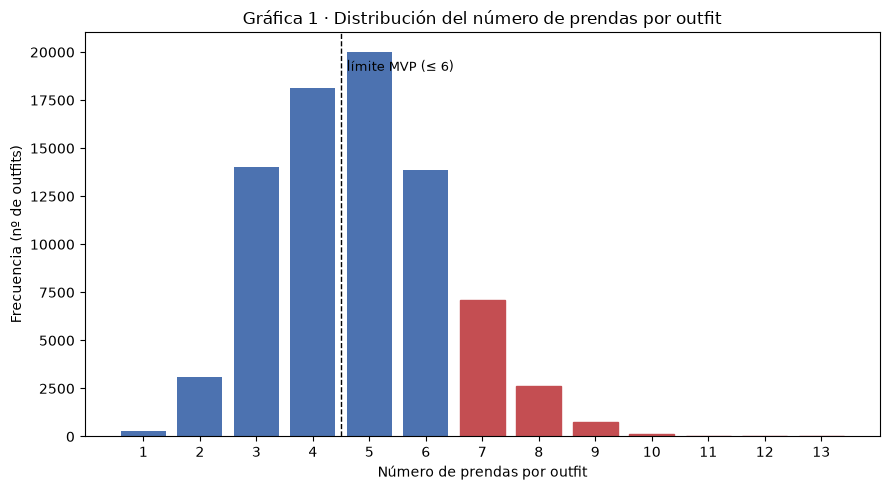

In [12]:
import matplotlib.pyplot as plt

# ---- Gráfica 1: distribución del número de prendas por outfit ----
fig, ax = plt.subplots(figsize=(9, 5))
counts = garments_per_outfit.value_counts().sort_index()
bars = ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")

# Resaltar el límite del MVP (<= 6 prendas)
for label, bar in zip(counts.index, bars):
    if label > 6:
        bar.set_color("#C44E52")
ax.axvline(x=3.5, color="black", linestyle="--", linewidth=1)
ax.text(3.6, max(counts.values) * 0.95, "límite MVP (≤ 6)", fontsize=9)

ax.set_xlabel("Número de prendas por outfit")
ax.set_ylabel("Frecuencia (nº de outfits)")
ax.set_title("Gráfica 1 · Distribución del número de prendas por outfit")
plt.tight_layout()
plt.show()

### 5b. Log EDA a MLflow (Tracking Quickstart Step 5: manual logging)

Registra parámetros y métricas del dataset para reproducibilidad. Ver https://mlflow.org/docs/latest/ml/tracking/quickstart/#step-5-log-a-model-and-metadata-manually


In [13]:
import mlflow
import tempfile
import matplotlib.pyplot as plt

# Apuntar directamente al servidor local
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Opcional: definir o seleccionar el experimento
mlflow.set_experiment("01-baseline-garments2look")

eda_params = {
    "dataset": "ArtmeScienceLab/Garments2Look",
    "n_outfits_total": int(len(raw_outfits)),
    "n_garments_catalog": int(len(garment_catalog)),
    "source": "mytheresa+polyvore",
}
eda_metrics = {
    "mean_garments_per_outfit": float(garments_per_outfit.mean()),
    "std_garments_per_outfit": float(garments_per_outfit.std()),
    "median_garments_per_outfit": float(garments_per_outfit.median()),
    "pct_sin_catalogo": float((~garments_df['en_catalogo']).mean() * 100),
    "n_categorias": int(garments_df['category'].nunique()),
    "n_subcategorias": int(garments_df['subcategory'].nunique()),
}

with mlflow.start_run(run_name="eda-metadata") as run:
    mlflow.log_params(eda_params)
    mlflow.log_metrics(eda_metrics)
    mlflow.set_tag("phase", "eda")
    mlflow.set_tag("notebook", "01_baseline")
    
    with tempfile.TemporaryDirectory() as tmp:
        csv_path = f"{tmp}/garments_per_outfit_counts.csv"
        garments_per_outfit.value_counts().sort_index().to_csv(csv_path, header=True)
        mlflow.log_artifact(csv_path, artifact_path="eda")

    print(f"[OK] MLflow run EDA: {run.info.run_id}")

2026/09/24 18:32:03 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/09/24 18:32:03 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/09/24 18:32:03 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/09/24 18:32:04 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


[OK] MLflow run EDA: 59584a1a311d47f7ae90631bb63aa395
🏃 View run eda-metadata at: http://127.0.0.1:5000/#/experiments/1/runs/59584a1a311d47f7ae90631bb63aa395
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


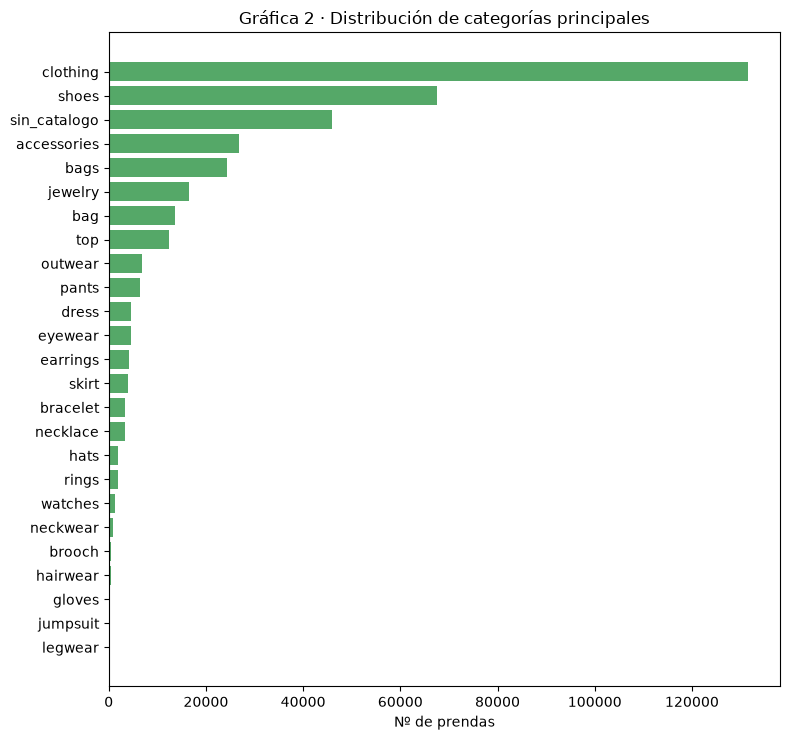

In [14]:
# ---- Gráfica 2: distribución de categorías principales ----
top_categories = garments_df["category"].value_counts().head(40)

fig, ax = plt.subplots(figsize=(8, max(6, len(top_categories) * 0.3)))
ax.barh(top_categories.index[::-1], top_categories.values[::-1], color="#55A868")
ax.set_xlabel("Nº de prendas")
ax.set_title("Gráfica 2 · Distribución de categorías principales")
plt.tight_layout()
plt.show()

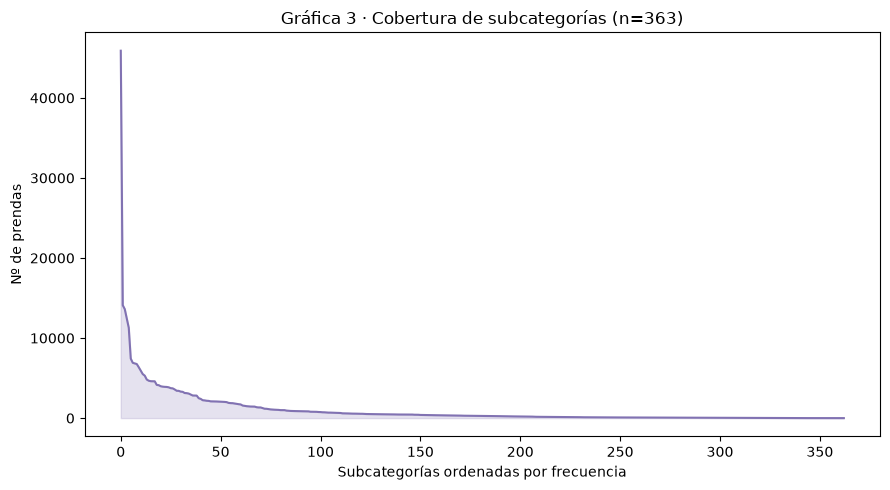

Subcategorías con >= 10 muestras: 331


In [15]:
# ---- Gráfica 3: cobertura de subcategorías ----
subcat_counts = garments_df["subcategory"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(len(subcat_counts)), subcat_counts.values, color="#8172B2")
ax.fill_between(range(len(subcat_counts)), subcat_counts.values, alpha=0.2, color="#8172B2")
ax.set_xlabel("Subcategorías ordenadas por frecuencia")
ax.set_ylabel("Nº de prendas")
ax.set_title(f"Gráfica 3 · Cobertura de subcategorías (n={subcat_counts.shape[0]})")
plt.tight_layout()
plt.show()

print(f"Subcategorías con >= 10 muestras: {(subcat_counts >= 10).sum()}")

## 6. EDA nivel 2: análisis de imágenes y galería visual (datos reales)

Las dimensiones se miden por streaming directo de polyvore/looks-resized.tar.gz (n=200) sin descargar los 284 GB, mediante requests con stream y tarfile en modo r|*. La galeria combina polyvore/images.tar.gz (prendas) y looks-resized (look final) con metadatos cruzados vía garment_catalog.


In [16]:
# Fallback visual solo si falta sample_data: no es dato de evaluación
def placeholder_imagen(texto, size=(200, 260), color=(230, 230, 230)):
    from PIL import ImageDraw
    from PIL import Image as PILImage2
    im = PILImage2.new("RGB", size, color)
    d = ImageDraw.Draw(im)
    d.text((8, 8), texto[:24], fill=(60, 60, 60))
    return im


Iniciando extracción por streaming...
Conectando al stream de: https://huggingface.co/datasets/ArtmeScienceLab/Garments2Look/resolve/main/polyvore/looks-resized.tar.gz
[OK] Extraídas 1/200 (última: 199736483.png)
[OK] Extraídas 50/200 (última: 193472465.png)
[OK] Extraídas 100/200 (última: 151591850.png)
[OK] Extraídas 150/200 (última: 216638569.png)
[OK] Extraídas 200/200 (última: 203007761.png)






Dimensión descriptiva de la muestra real:


,width,height,aspect_ratio
count,200.0,200.0,200.000000
mean,585.0,1024.0,0.571289
std,0.0,0.0,0.000000
min,585.0,1024.0,0.571289
25%,585.0,1024.0,0.571289
50%,585.0,1024.0,0.571289
75%,585.0,1024.0,0.571289
max,585.0,1024.0,0.571289


In [17]:
import requests
import tarfile
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def extraer_n_imagenes_streaming(repo_id, filename, n_images=200):
    """
    Se conecta al archivo .tar.gz en Hugging Face y extrae N imágenes al vuelo
    sin descargar el archivo completo a disco ni a memoria.
    """
    url = f"https://huggingface.co/datasets/{repo_id}/resolve/main/{filename}"
    print(f"Conectando al stream de: {url}")
    
    # stream=True descarga únicamente los bytes necesarios a medida que leemos el stream
    response = requests.get(url, stream=True)
    response.raise_for_status()
    
    imagenes = []
    # "r|*" le indica a tarfile que lea de un stream secuencial
    with tarfile.open(fileobj=response.raw, mode="r|*") as tar:
        for member in tar:
            if member.isreg() and member.name.lower().endswith(('.png', '.jpg', '.jpeg')):
                f = tar.extractfile(member)
                if f is not None:
                    img = Image.open(f).convert("RGB")
                    img.thumbnail((768, 1024)) 
                    imagenes.append((member.name, img))
                    n = len(imagenes)
                    if n == 1 or n % 50 == 0 or n >= n_images:
                        print(f"[OK] Extraídas {n}/{n_images} (última: {member.name.split('/')[-1]})")
                    
                    if len(imagenes) >= n_images:
                        break
    return imagenes

# 1. Configurar la ruta exacta dentro del repositorio
REPO_ID = "ArtmeScienceLab/Garments2Look"
TAR_FILENAME = "polyvore/looks-resized.tar.gz"

print("Iniciando extracción por streaming...")
try:
    imagenes_muestra = extraer_n_imagenes_streaming(REPO_ID, TAR_FILENAME, n_images=200)
except Exception as e:
    print(f"[WARN] Error en el streaming: {e}")
    imagenes_muestra = []

# 2. Extraer keypoints y visualizar
if imagenes_muestra:
    cols = 5
    rows = (len(imagenes_muestra) + cols - 1)//cols
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
    axes = __import__("numpy").atleast_1d(axes).flatten()

    
    for i, (nombre_archivo, img) in enumerate(imagenes_muestra):
        ax = axes[i]
        
        if 'dwpose_disponible' in globals() and dwpose_disponible:
            img_procesada = dwpose(img) 
            ax.imshow(img_procesada)
            ax.set_title(f"Pose (18 pts) - {nombre_archivo.split('/')[-1][:12]}...", fontsize=9)
        else:
            ax.imshow(img)
            ax.set_title(f"Orig - {nombre_archivo.split('/')[-1][:12]}...", fontsize=9)
            
        ax.axis('off')
    for j in range(len(imagenes_muestra), len(axes)):
        axes[j].axis('off')
        
    plt.suptitle(f"Galería de Muestra: {len(imagenes_muestra)} Imágenes Reales con DWPose (Streaming)", fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # 3. Construir el DataFrame con métricas reales usando la muestra extraída
    img_dims = pd.DataFrame([
        {"width": img.width, "height": img.height} 
        for _, img in imagenes_muestra
    ])
    img_dims["aspect_ratio"] = img_dims["width"] / img_dims["height"]
    print("\nDimensión descriptiva de la muestra real:")
    display(img_dims.describe())

else:
    print("No se pudieron extraer imágenes. Revisa que el token o los permisos del repo sean válidos.")


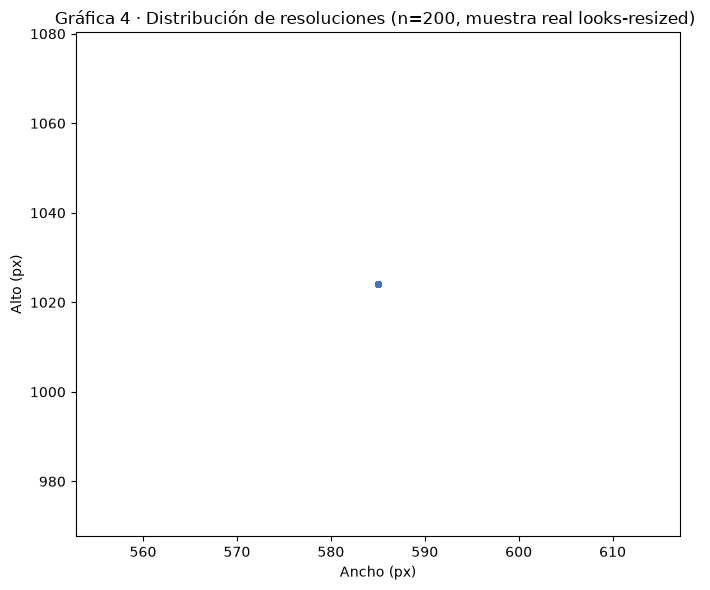

In [18]:
# ---- Gráfica 4: distribución de resoluciones (W x H)  ----
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(img_dims["width"], img_dims["height"], alpha=0.3, s=15, color="#4C72B0")
ax.set_xlabel("Ancho (px)")
ax.set_ylabel("Alto (px)")
ax.set_title("Gráfica 4 · Distribución de resoluciones (n=200, muestra real looks-resized) ")
plt.tight_layout()
plt.show()


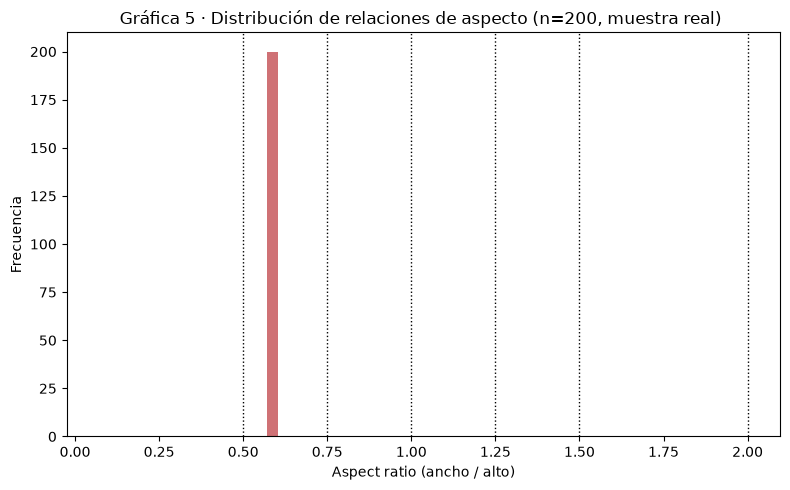

In [19]:
# ---- Gráfica 5: distribución de relación de aspecto  ----
bins_referencia = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(img_dims["aspect_ratio"], bins=30, color="#C44E52", alpha=0.8)
for b in bins_referencia:
    ax.axvline(x=b, color="black", linestyle=":", linewidth=1)
ax.set_xlabel("Aspect ratio (ancho / alto)")
ax.set_ylabel("Frecuencia")
ax.set_title("Gráfica 5 · Distribución de relaciones de aspecto (n=200, muestra real) ")
plt.tight_layout()
plt.show()


Conectando al stream de prendas: https://huggingface.co/datasets/ArtmeScienceLab/Garments2Look/resolve/main/polyvore/images.tar.gz
[OK] Prenda 1/6: ID 100002074_3 | bag
[OK] Prenda 2/6: ID 100095342_5 | bag
[OK] Prenda 3/6: ID 100111991_4 | bag
[OK] Prenda 4/6: ID 100119147_4 | bag
[OK] Prenda 5/6: ID 100119331_4 | bag
[OK] Prenda 6/6: ID 10014953_9 | bag


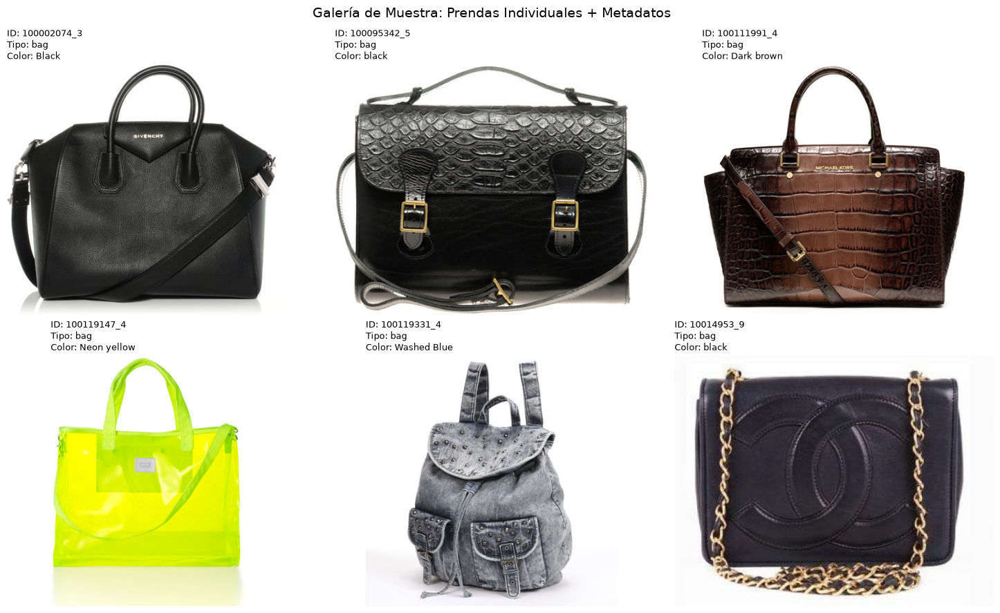


Metadatos detallados de la muestra de prendas:


,Garment ID,Nombre / Descripción,Tipo / Categoría,Color,Categoría Principal,Resolución
0,100002074_3,Givenchy Antigona Black Pebbled Leather Handbag,bag,Black,bag,400x351
1,100095342_5,Black Croc Embossed Leather Satchel,bag,black,bag,400x319
2,100111991_4,Michael Kors Croc-Embossed Graduated Brown Tote,bag,Dark brown,bag,400x379
3,100119147_4,Neon Yellow Clear Transparent Tote Bag,bag,Neon yellow,bag,316x400
4,100119331_4,Acid Wash Studded Denim Drawstring Backpack,bag,Washed Blue,bag,400x397
5,10014953_9,Chanel Black Leather CC Logo Shoulder Bag,bag,black,bag,324x254


In [20]:
import os
import requests
import tarfile
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

def extraer_prendas_con_metadatos(repo_id, tar_filename, catalog, n_images=6):
    """
    Lee 'polyvore/images.tar.gz' por streaming, extrae N fotos de prendas,
    obtiene su garment_id y recupera los metadatos desde garment_catalog.
    """
    url = f"https://huggingface.co/datasets/{repo_id}/resolve/main/{tar_filename}"
    print(f"Conectando al stream de prendas: {url}")
    
    response = requests.get(url, stream=True)
    response.raise_for_status()
    
    prendas_extraidas = []
    
    with tarfile.open(fileobj=response.raw, mode="r|*") as tar:
        for member in tar:
            if member.isreg() and member.name.lower().endswith(('.png', '.jpg', '.jpeg')):
                # Extraer garment_id desde el nombre del archivo (ej. "path/123456.jpg" -> "123456")
                nombre_base = os.path.basename(member.name)
                garment_id = os.path.splitext(nombre_base)[0]
                
                f = tar.extractfile(member)
                if f is not None:
                    img = Image.open(f).convert("RGB")
                    img.thumbnail((400, 500))  # Tamaño compacto para prendas
                    
                    # Recuperar metadatos del catálogo cargado
                    meta = catalog.get(garment_id, {})
                    
                    prendas_extraidas.append({
                        "garment_id": garment_id,
                        "image": img,
                        "type": meta.get("type", "desconocido"),
                        "color": meta.get("color", "N/A"),
                        "name": meta.get("name", "Sin nombre"),
                        "main_category": meta.get("main_category", "N/A"),
                        "raw_meta": meta
                    })
                    
                    print(f"[OK] Prenda {len(prendas_extraidas)}/{n_images}: ID {garment_id} | {meta.get('type', 'N/A')}")
                    
                    if len(prendas_extraidas) >= n_images:
                        break
                        
    return prendas_extraidas

# 1. Configuración de streaming para el catálogo de prendas
TAR_PRENDAS = "polyvore/images.tar.gz"

try:
    prendas_muestra = extraer_prendas_con_metadatos(
        REPO_ID, TAR_PRENDAS, garment_catalog, n_images=6
    )
except Exception as e:
    print(f"[WARN] Error al extraer prendas: {e}")
    prendas_muestra = []

# 2. Visualización en galería con metadatos
if prendas_muestra:
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()
    
    for i, item in enumerate(prendas_muestra):
        ax = axes[i]
        ax.imshow(item["image"])
        
        # Título formateado con ID, Categoría y Color
        cat_corta = item['type'].split('::')[-1] if '::' in item['type'] else item['type']
        titulo = f"ID: {item['garment_id']}\nTipo: {cat_corta}\nColor: {item['color']}"
        
        ax.set_title(titulo, fontsize=9, loc='left', pad=6)
        ax.axis('off')
        
    plt.suptitle("Galería de Muestra: Prendas Individuales + Metadatos", fontsize=14)
    plt.tight_layout()
    plt.show()

    # 3. Tabla resumen de metadatos extraídos
    df_meta = pd.DataFrame([
        {
            "Garment ID": p["garment_id"],
            "Nombre / Descripción": p["name"],
            "Tipo / Categoría": p["type"],
            "Color": p["color"],
            "Categoría Principal": p["main_category"],
            "Resolución": f"{p['image'].width}x{p['image'].height}"
        }
        for p in prendas_muestra
    ])
    
    print("\nMetadatos detallados de la muestra de prendas:")
    display(df_meta)

## 7. Segmentación del subconjunto candidato MVP (hasta 6 prendas)

El MVP limita cada outfit a un máximo de 6 elementos: top o camiseta, camisa o polera, pantalón o falda, chaqueta o abrigo, calzado y un accesorio. Esta sección mide qué porcentaje del dataset ya cumple esa restricción sin recortes.

Outfits totales: 80041
Outfits con ≤ 6 prendas: 69428 (86.7%)
Outfits que requerirían recorte (> 6 prendas): 10613 (13.3%)


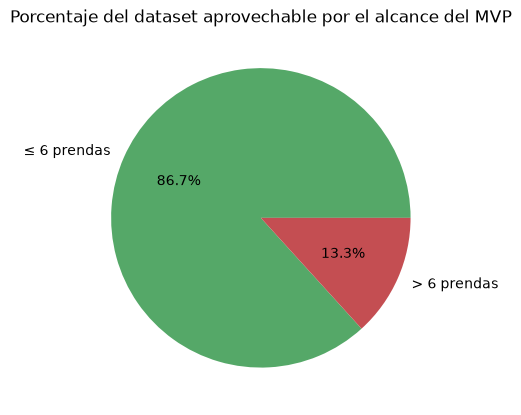

In [21]:
MAX_PRENDAS_MVP = 6

outfits_df["apto_mvp"] = outfits_df["n_garments"] <= MAX_PRENDAS_MVP
n_aptos = outfits_df["apto_mvp"].sum()
pct_aptos = 100 * n_aptos / len(outfits_df)

print(f"Outfits totales: {len(outfits_df)}")
print(f"Outfits con ≤ {MAX_PRENDAS_MVP} prendas: {n_aptos} ({pct_aptos:.1f}%)")
print(f"Outfits que requerirían recorte (> {MAX_PRENDAS_MVP} prendas): "
      f"{len(outfits_df) - n_aptos} ({100 - pct_aptos:.1f}%)")

mvp_subset_df = outfits_df[outfits_df["apto_mvp"]].copy()
mvp_subset_ids = set(mvp_subset_df["outfit_id"])
mvp_outfits = [o for o in raw_outfits if o["outfit_id"] in mvp_subset_ids]

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(
    [n_aptos, len(outfits_df) - n_aptos],
    labels=[f"≤ {MAX_PRENDAS_MVP} prendas", f"> {MAX_PRENDAS_MVP} prendas"],
    autopct="%1.1f%%",
    colors=["#55A868", "#C44E52"],
)
ax.set_title("Porcentaje del dataset aprovechable por el alcance del MVP")
plt.tight_layout()
plt.show()

## 8. Preprocesamiento de pose de usuario (MediaPipe y DWPose)

MediaPipe verifica que la foto de entrada cumpla la condición de A-Pose en postura y encuadre frontal antes de continuar. DWPose extrae los keypoints anatómicos de hombros, codos, muñecas, caderas, rodillas y tobillos para la etapa de alineamiento y máscaras.

Utilizar una foto propia en A-Pose con fondo neutro y colocarla en `USER_IMAGE_PATH`.

In [22]:
# ---- Carga y preparación de la imagen de usuario ----

import os
import cv2
import numpy as np

USER_IMAGE_PATH = str(REPO_ROOT / "sample_data/usuario_apose.jpg")


def cargar_imagen_bgr(path):
    """
    Carga una imagen desde disco usando OpenCV.
    Si no existe, genera una imagen gris de ejemplo.
    """
    if not os.path.exists(path):
        print(f"[WARN] No se encontró {path}; generando imagen de ejemplo en gris.")
        return np.full((1024, 768, 3), 200, dtype=np.uint8)

    imagen = cv2.imread(path)

    if imagen is None:
        print(f"[WARN] OpenCV no pudo leer {path}; generando imagen de ejemplo en gris.")
        return np.full((1024, 768, 3), 200, dtype=np.uint8)

    return imagen


# Cargar imagen en formato BGR
user_img_bgr = cargar_imagen_bgr(USER_IMAGE_PATH)

# Convertir BGR -> RGB
user_img_rgb = cv2.cvtColor(user_img_bgr, cv2.COLOR_BGR2RGB)

print("Dimensiones de la imagen de usuario:", user_img_rgb.shape)

Dimensiones de la imagen de usuario: (1428, 720, 3)


In [23]:
# ---- Validación de A-Pose con MediaPipe (API moderna) ----

import os
import urllib.request
import mediapipe as mp

# 1. Descargar automáticamente el modelo Pose Landmarker

MODEL_PATH = str(REPO_ROOT / "pose_landmarker_full.task")

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "pose_landmarker/pose_landmarker_full/float16/latest/"
    "pose_landmarker_full.task"
)

if not os.path.exists(MODEL_PATH):
    print("[INFO] Descargando modelo de MediaPipe Pose Landmarker...")

    try:
        urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
        print("[OK] Modelo descargado correctamente.")

    except Exception as e:
        raise RuntimeError(
            f"No se pudo descargar el modelo de MediaPipe.\n"
            f"URL: {MODEL_URL}\n"
            f"Error: {e}"
        )

else:
    print("[OK] Modelo de MediaPipe ya existe.")


# 2. Configurar Pose Landmarker

BaseOptions = mp.tasks.BaseOptions
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode


options = PoseLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=MODEL_PATH
    ),
    running_mode=RunningMode.IMAGE,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5
)


# 3. Crear detector

pose_detector = PoseLandmarker.create_from_options(options)


# 4. Validación de A-Pose

def validar_a_pose(imagen_rgb, umbral_apertura_brazos=0.05):
    """
    Valida de forma simple si la persona presenta una A-Pose.

    La comprobación compara la separación horizontal de las
    muñecas respecto a los hombros.
    """

    # MediaPipe Image desde RGB
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=imagen_rgb
    )

    # Ejecutar detección
    resultado = pose_detector.detect(mp_image)

    # No se detectó ninguna persona

    if not resultado.pose_landmarks:
        return False, None, "No se detectó una persona en la imagen."

    # Primera persona detectada
    lm = resultado.pose_landmarks[0]

    # Índices de landmarks de BlazePose

    LEFT_SHOULDER = 11
    RIGHT_SHOULDER = 12

    LEFT_WRIST = 15
    RIGHT_WRIST = 16

    # Obtener puntos
    hombro_izq = lm[LEFT_SHOULDER]
    hombro_der = lm[RIGHT_SHOULDER]

    muneca_izq = lm[LEFT_WRIST]
    muneca_der = lm[RIGHT_WRIST]

    # Ancho horizontal de hombros

    ancho_hombros = abs(
        hombro_der.x - hombro_izq.x
    )

    if ancho_hombros <= 0:
        return (
            False,
            resultado.pose_landmarks,
            "No se pudo calcular correctamente el ancho de hombros."
        )

    # Separación horizontal de las muñecas

    separacion_izq = abs(
        muneca_izq.x - hombro_izq.x
    )

    separacion_der = abs(
        muneca_der.x - hombro_der.x
    )

    # Validar A-Pose

    es_apose = (
        separacion_izq >
        umbral_apertura_brazos * ancho_hombros
        and
        separacion_der >
        umbral_apertura_brazos * ancho_hombros
    )

    # Mensaje

    mensaje = (
        "A-Pose válida [OK]"
        if es_apose
        else
        "La postura no parece A-Pose [WARN]"
    )

    return (
        es_apose,
        resultado.pose_landmarks,
        mensaje
    )


# 5. Ejecutar validación

es_valida, landmarks_mp, mensaje = validar_a_pose(
    user_img_rgb
)

print(mensaje)

[OK] Modelo de MediaPipe ya existe.
La postura no parece A-Pose [WARN]


[INFO] DWPose no disponible: module 'mediapipe' has no attribute 'solutions'
[OK] Modelo Pose Landmarker ya existe
[OK] Keypoints dibujados con MediaPipe Pose Landmarker
[OK] Procesamiento de pose finalizado


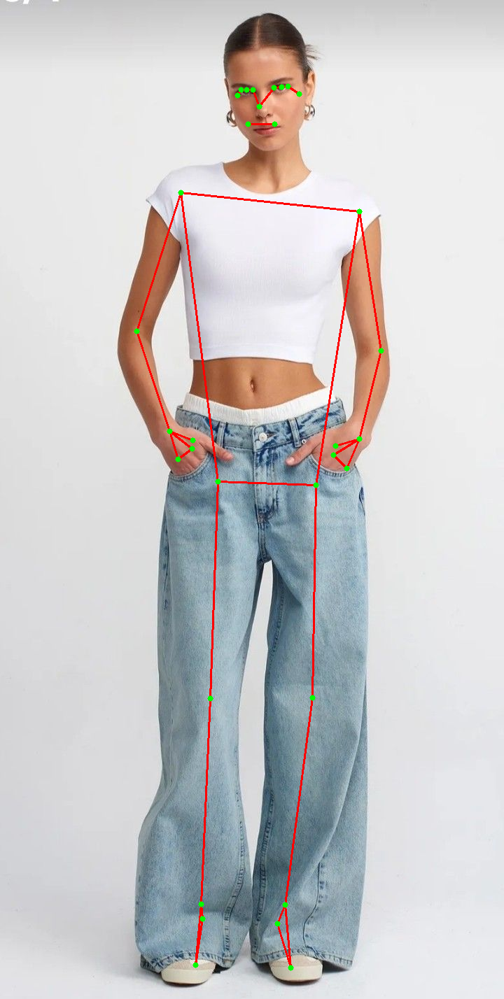

In [24]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="controlnet_aux")

from pathlib import Path
from PIL import Image as PILImage
import numpy as np
import urllib.request
import cv2

user_img_pil = PILImage.fromarray(user_img_rgb)

# ============================================================
# 1. INTENTO DWPose
# ============================================================
dwpose_disponible = False
dwpose = None

try:
    from controlnet_aux.dwpose import DWposeDetector

    if hasattr(DWposeDetector, "from_pretrained"):
        dwpose = DWposeDetector.from_pretrained("yzd-v/DWPose")
        dwpose_disponible = True
        print("[OK] DWPose cargado mediante from_pretrained()")
    else:
        print("[INFO] Tu versión de controlnet_aux no expone DWposeDetector.from_pretrained()")
        print("[INFO] Se continuará con MediaPipe Tasks.")

except Exception as e:
    print(f"[INFO] DWPose no disponible: {e}")


# ============================================================
# 2. INFERENCIA DWPose
# ============================================================
keypoints_overlay = None

if dwpose_disponible:
    try:
        keypoints_overlay = dwpose(
            user_img_pil,
            output_type="pil",
            include_hands=True,
            include_face=True
        )

        print("[OK] Keypoints generados con DWPose")

    except Exception as e:
        print(f"[WARN] Inferencia DWPose falló: {e}")
        dwpose_disponible = False


# ============================================================
# 3. FALLBACK: MEDIAPIPE TASKS
# ============================================================
if not dwpose_disponible:

    try:
        import mediapipe as mp
        from mediapipe.tasks import python
        from mediapipe.tasks.python import vision

        # --------------------------------------------------------
        # Carpeta para el modelo
        # --------------------------------------------------------
        MODEL_DIR = Path("models")
        MODEL_DIR.mkdir(exist_ok=True)

        pose_model_path = MODEL_DIR / "pose_landmarker_full.task"

        # --------------------------------------------------------
        # URL CORRECTA DEL MODELO
        # --------------------------------------------------------
        model_url = (
            "https://storage.googleapis.com/"
            "mediapipe-models/"
            "pose_landmarker/"
            "pose_landmarker_full/"
            "float16/"
            "1/"
            "pose_landmarker_full.task"
        )

        # --------------------------------------------------------
        # Descargar modelo
        # --------------------------------------------------------
        if not pose_model_path.exists():

            print("[INFO] Descargando modelo Pose Landmarker...")
            print(f"[INFO] URL: {model_url}")

            urllib.request.urlretrieve(
                model_url,
                pose_model_path
            )

            print("[OK] Modelo descargado")

        else:
            print("[OK] Modelo Pose Landmarker ya existe")

        # --------------------------------------------------------
        # Configurar Pose Landmarker
        # --------------------------------------------------------
        base_options = python.BaseOptions(
            model_asset_path=str(pose_model_path)
        )

        options = vision.PoseLandmarkerOptions(
            base_options=base_options,
            running_mode=vision.RunningMode.IMAGE,
            num_poses=1,
            min_pose_detection_confidence=0.5,
            min_pose_presence_confidence=0.5,
            min_tracking_confidence=0.5
        )

        # --------------------------------------------------------
        # Crear detector
        # --------------------------------------------------------
        with vision.PoseLandmarker.create_from_options(options) as landmarker:

            # Convertir imagen a MediaPipe
            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=np.asarray(user_img_rgb)
            )

            # Inferencia
            results = landmarker.detect(mp_image)

        # --------------------------------------------------------
        # Dibujar resultado
        # --------------------------------------------------------
        annotated_img = user_img_rgb.copy()

        if results.pose_landmarks:

            h, w = annotated_img.shape[:2]
            landmarks = results.pose_landmarks[0]

            # Conexiones oficiales del Pose Landmarker
            connections = vision.PoseLandmarksConnections.POSE_LANDMARKS

            # Dibujar conexiones
            for connection in connections:

                start = landmarks[connection.start]
                end = landmarks[connection.end]

                x1 = int(start.x * w)
                y1 = int(start.y * h)

                x2 = int(end.x * w)
                y2 = int(end.y * h)

                if (
                    0 <= x1 < w and
                    0 <= y1 < h and
                    0 <= x2 < w and
                    0 <= y2 < h
                ):
                    cv2.line(
                        annotated_img,
                        (x1, y1),
                        (x2, y2),
                        (255, 0, 0),
                        2
                    )

            # Dibujar puntos
            for landmark in landmarks:

                x = int(landmark.x * w)
                y = int(landmark.y * h)

                if 0 <= x < w and 0 <= y < h:

                    cv2.circle(
                        annotated_img,
                        (x, y),
                        4,
                        (0, 255, 0),
                        -1
                    )

            print("[OK] Keypoints dibujados con MediaPipe Pose Landmarker")

        else:
            print("[WARN] MediaPipe no detectó ninguna persona")

        keypoints_overlay = PILImage.fromarray(annotated_img)

    except Exception as e_mp:

        print(f"[ERR] Fallback MediaPipe también falló: {e_mp}")

        keypoints_overlay = user_img_pil


# ============================================================
# 4. RESULTADO
# ============================================================
print("[OK] Procesamiento de pose finalizado")

keypoints_overlay

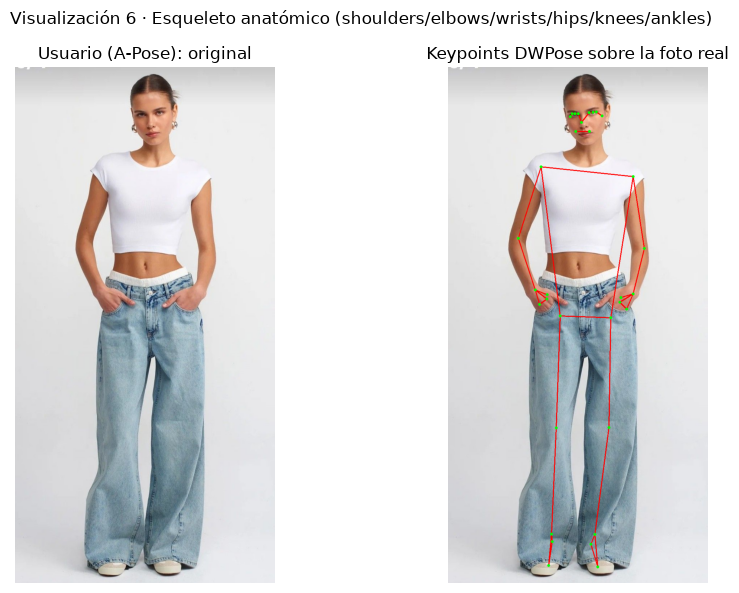

In [25]:
# ---- Visualización 6: foto original vs. esqueleto de keypoints ----
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(user_img_rgb)
axes[0].set_title("Usuario (A-Pose): original")
axes[0].axis("off")

axes[1].imshow(keypoints_overlay)
axes[1].set_title("Keypoints DWPose sobre la foto real")
axes[1].axis("off")

plt.suptitle("Visualización 6 · Esqueleto anatómico (shoulders/elbows/wrists/hips/knees/ankles)")
plt.tight_layout()
plt.show()

## 9. Baseline CatVTON: inferencia con una prenda

Primer experimento reproducible:

```
Usuario (A-Pose) + Prenda (fondo neutro) -> CatVTON -> Imagen generada
```

Requiere GPU con al menos 12 GB de VRAM. Si la carpeta `CatVTON` no está clonada o faltan los pesos, la celda informa qué falta y continúa sin interrumpir el resto del notebook.

In [47]:
# ============================================================
# 9. Baseline CatVTON: preparación para inferencia
# ============================================================

import sys
from pathlib import Path

CATVTON_DISPONIBLE = False

# Usar IS_COLAB y REPO_ROOT definidos en Sección 1 (Configuración)
if IS_COLAB:
    CATVTON_DIR = Path("/content/CatVTON")
else:
    candidates = [
        REPO_ROOT.parent / "CatVTON",
        REPO_ROOT / "CatVTON",
        Path.cwd().resolve() / "CatVTON",
        Path.cwd().resolve().parent / "CatVTON",
    ]
    CATVTON_DIR = next((c for c in candidates if c.exists()), candidates[0])

print(f"CatVTON dir: {CATVTON_DIR}")

if IS_COLAB and not CATVTON_DIR.exists():
    print(f"Clonando CatVTON en {CATVTON_DIR}...")
    import subprocess
    subprocess.run(["git", "clone", "https://github.com/Zheng-Chong/CatVTON.git", str(CATVTON_DIR)], check=True)
    print(f"Clonado en {CATVTON_DIR}")

if not CATVTON_DIR.exists():
    print("[ERR] No se encontro CatVTON.")
    print(f"   Ruta: {CATVTON_DIR}")
    if not IS_COLAB:
        print("   En local: git clone https://github.com/Zheng-Chong/CatVTON.git al lado de MACHINE-BULLS")
else:
    print("[OK] CatVTON encontrado.")
    MODEL_DIR = CATVTON_DIR / "model"
    UTILS_FILE = CATVTON_DIR / "utils.py"
    if not MODEL_DIR.exists():
        print(f"[ERR] Falta {MODEL_DIR}")
    elif not UTILS_FILE.exists():
        print(f"[ERR] Falta {UTILS_FILE}")
    else:
        print("[OK] model/ y utils.py OK")
        catvton_path = str(CATVTON_DIR.resolve())
        if catvton_path not in sys.path:
            sys.path.insert(0, catvton_path)
        print(f"[OK] PYTHONPATH: {catvton_path}")
        try:
            from model.pipeline import CatVTONPipeline
            from model.cloth_masker import AutoMasker, vis_mask
            from utils import resize_and_crop, resize_and_padding, init_weight_dtype
            from diffusers.image_processor import VaeImageProcessor
            from huggingface_hub import snapshot_download
            CATVTON_DISPONIBLE = True
            print("\n[OK] CatVTON importado")
        except Exception as e:
            CATVTON_DISPONIBLE = False
            print(f"\n[ERR] Import fallo: {type(e).__name__}: {e}")
    print(f"\nCATVTON_DISPONIBLE = {CATVTON_DISPONIBLE}")


CatVTON dir: E:\MACHINEBULLS\CatVTON
[OK] CatVTON encontrado.
[OK] model/ y utils.py OK
[OK] PYTHONPATH: E:\MACHINEBULLS\CatVTON

[OK] CatVTON importado

CATVTON_DISPONIBLE = True


In [48]:
if CATVTON_DISPONIBLE:
    TARGET_SIZE = (768, 1024)
    import os as _os
    _os.environ["HF_HUB_VERBOSITY"] = "error"
    try:
        from huggingface_hub.utils import disable_progress_bars
        disable_progress_bars()
    except Exception:
        pass

    # --- Selección de dtype óptimo para tu GPU ---
    if torch.cuda.is_available():
        if torch.cuda.is_bf16_supported():
            # Ampere o más nuevo (RTX 30/40, A100...): mismo rango dinámico que fp32,
            # evita los NaN/salidas planas típicos de fp16 -- SIN necesidad de forzar la VAE aparte.
            CATVTON_DTYPE = torch.bfloat16
        else:
            CATVTON_DTYPE = torch.float16
        print(f"[INFO] GPU: {torch.cuda.get_device_name(0)} -> dtype = {CATVTON_DTYPE}")
    else:
        CATVTON_DTYPE = torch.float32
        print("[INFO] Sin GPU -> dtype = float32")

    torch.backends.cudnn.benchmark = True

    repo_pesos = snapshot_download(repo_id="zhengchong/CatVTON")
    catvton_pipeline = CatVTONPipeline(
        base_ckpt="runwayml/stable-diffusion-inpainting",
        attn_ckpt=repo_pesos,
        attn_ckpt_version="mix",
        weight_dtype=CATVTON_DTYPE,   # UNet, VAE y attn_modules quedan TODOS en el mismo dtype (uniforme)
        use_tf32=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        skip_safety_check=True,
    )
    # (Se quitó el override de la VAE a fp32: con bf16 no hace falta y rompía la concatenación interna del pipeline)

    automasker = AutoMasker(
        densepose_ckpt=os.path.join(repo_pesos, "DensePose"),
        schp_ckpt=os.path.join(repo_pesos, "SCHP"),
        device="cuda" if torch.cuda.is_available() else "cpu",
    )
    mask_processor = VaeImageProcessor(
        vae_scale_factor=8, do_normalize=False, do_binarize=True, do_convert_grayscale=True,
    )
    print("[OK] Pipeline CatVTON y AutoMasker cargados (safety_check desactivado).")
else:
    print("Saltando carga de CatVTON (no disponible en este entorno).")

[INFO] GPU: NVIDIA GeForce RTX 4070 Laptop GPU -> dtype = torch.bfloat16


An error occurred while trying to fetch runwayml/stable-diffusion-inpainting: runwayml/stable-diffusion-inpainting does not appear to have a file named diffusion_pytorch_model.safetensors.


[OK] Pipeline CatVTON y AutoMasker cargados (safety_check desactivado).


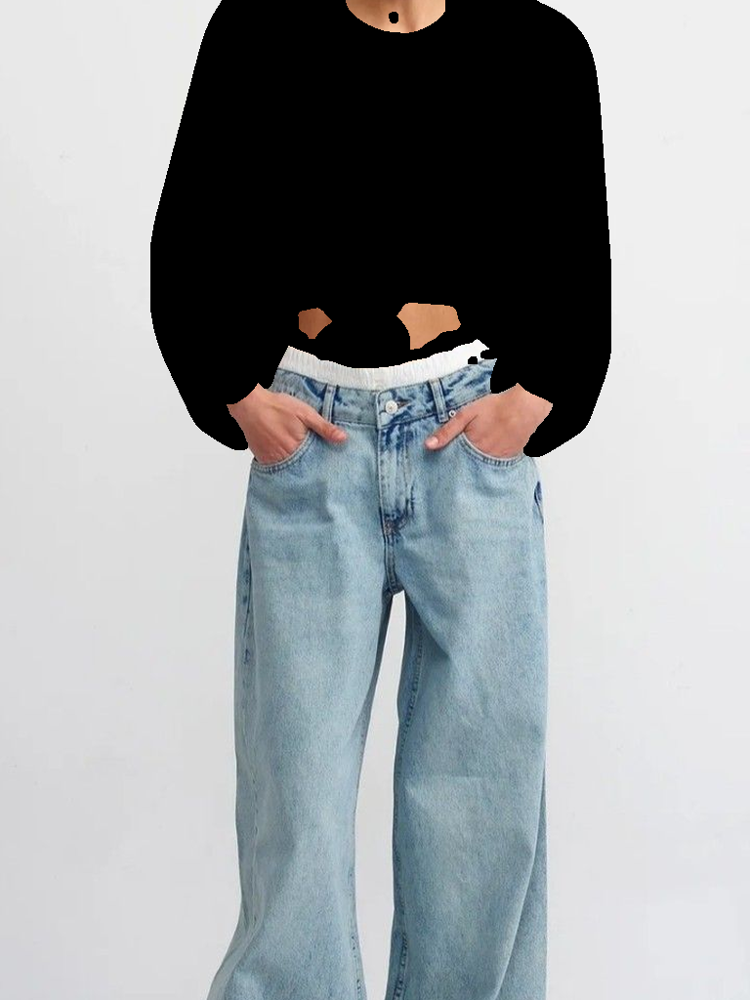

100%|██████████| 75/75 [01:15<00:00,  1.01s/it]


[OK] Seed 42 generada


100%|██████████| 75/75 [07:44<00:00,  6.19s/it] 


[OK] Seed 123 generada


100%|██████████| 75/75 [01:13<00:00,  1.02it/s]


[OK] Seed 7 generada


100%|██████████| 75/75 [01:13<00:00,  1.02it/s]


[OK] Seed 2024 generada


In [49]:
from model.cloth_masker import vis_mask

def generar_tryon(persona_pil, prenda_pil, tipo_prenda="upper", pasos=75, guidance=2.5, seed=42, mostrar_mascara=False):
    """Ejecuta una pasada de CatVTON: persona + prenda -> imagen generada.
    Devuelve (persona_redimensionada, prenda_redimensionada, resultado_pil, mascara)."""
    persona_r = resize_and_crop(persona_pil, TARGET_SIZE)
    prenda_r = resize_and_padding(prenda_pil, TARGET_SIZE)

    mask = automasker(persona_r, tipo_prenda)["mask"]

    if mostrar_mascara:
        display(vis_mask(persona_r, mask))  # inspección visual: ¿cubre bien el torso o se corta como el crop top?

    mask_blur = mask_processor.blur(mask, blur_factor=9)

    generador = torch.Generator(
        device="cuda" if torch.cuda.is_available() else "cpu"
    ).manual_seed(seed)

    resultado = catvton_pipeline(
        image=persona_r,
        condition_image=prenda_r,
        mask=mask_blur,
        num_inference_steps=pasos,
        guidance_scale=guidance,
        generator=generador,
    )[0]
    return persona_r, prenda_r, resultado, mask


GARMENT_IMAGE_PATH = str(REPO_ROOT / "sample_data/prenda_camiseta.jpg")

if CATVTON_DISPONIBLE:
    prenda_pil = PILImage.open(GARMENT_IMAGE_PATH).convert("RGB") if os.path.exists(GARMENT_IMAGE_PATH) \
        else placeholder_imagen("CAMISETA", size=(768, 1024), color=(245, 220, 210))

    # --- Modo "máxima calidad": generamos con varias seeds y comparamos ---
    SEMILLAS = [42, 123, 7, 2024]
    resultados_por_seed = {}
    for i, s in enumerate(SEMILLAS):
        persona_r, prenda_r, resultado_s, mascara_s = generar_tryon(
            user_img_pil, prenda_pil, tipo_prenda="upper",
            pasos=75, guidance=2.5, seed=s,
            mostrar_mascara=(i == 0),  # solo mostramos la máscara una vez, es la misma para todas las seeds
        )
        resultados_por_seed[s] = resultado_s
        print(f"[OK] Seed {s} generada")

    resultado_1 = resultados_por_seed[SEMILLAS[0]]  # para no romper la Visualización 7 tal cual la tenías
else:
    print("Saltando inferencia (CatVTON no disponible).")

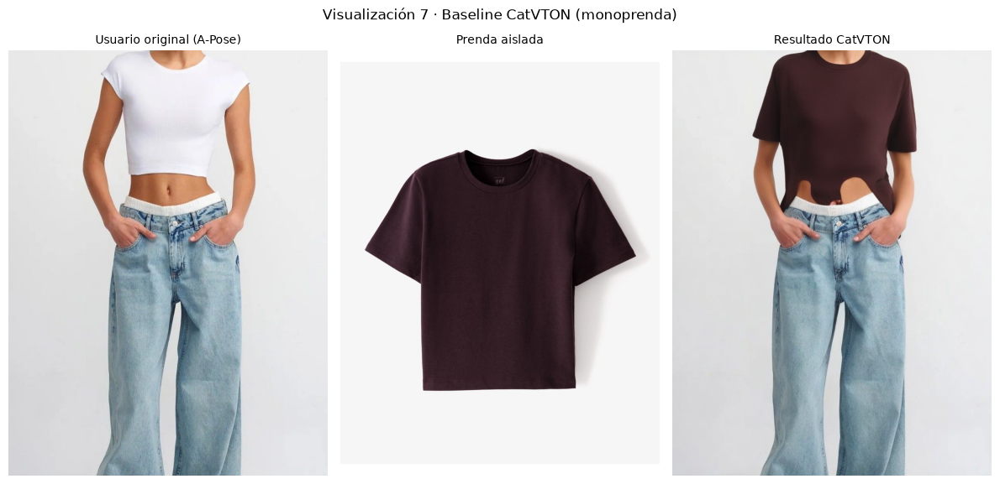

ValueError: Number of columns must be a positive integer, not 0

<Figure size 0x600 with 0 Axes>

In [46]:
%matplotlib inline
# ---- Visualización 7: comparativa triple (usuario | prenda | resultado) ----
if CATVTON_DISPONIBLE:
    fig, axes = plt.subplots(1, 3, figsize=(12, 6))
    for ax, img, titulo in zip(
        axes,
        [persona_r, prenda_r, resultado_1],
        ["Usuario original (A-Pose)", "Prenda aislada", "Resultado CatVTON"],
    ):
        ax.imshow(img)
        ax.set_title(titulo, fontsize=10)
        ax.axis("off")
    plt.suptitle("Visualización 7 · Baseline CatVTON (monoprenda)")
    plt.tight_layout()
    plt.show()

    # ---- Visualización 7B: comparación entre seeds (para elegir el mejor resultado) ----
    n = len(resultados_por_seed)
    fig2, axes2 = plt.subplots(1, n, figsize=(4 * n, 6))
    for ax, (s, img) in zip(axes2, resultados_por_seed.items()):
        ax.imshow(img)
        ax.set_title(f"seed={s}", fontsize=10)
        ax.axis("off")
    plt.suptitle("Visualización 7B · Comparación de seeds (mismo pipeline, distinta semilla)")
    plt.tight_layout()
    plt.show()
else:
    print("Sin resultado que visualizar (CatVTON no disponible en este entorno).")

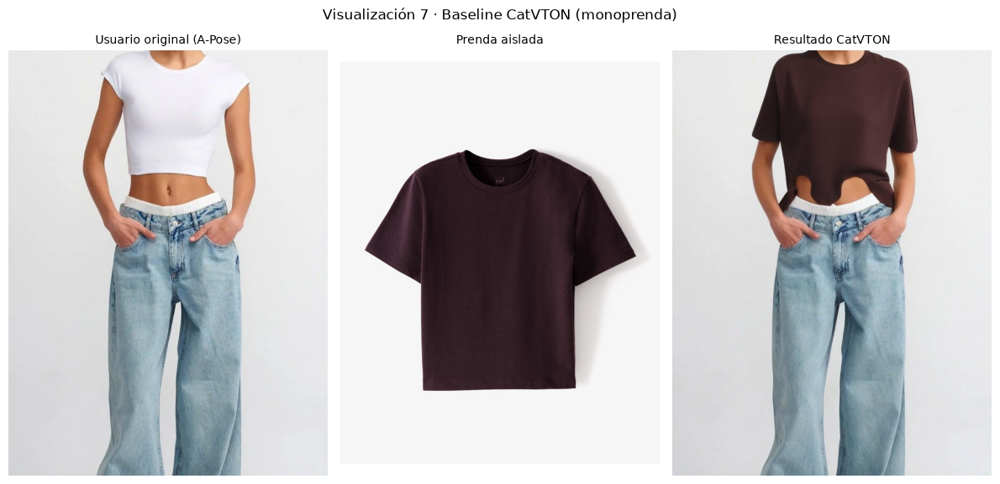

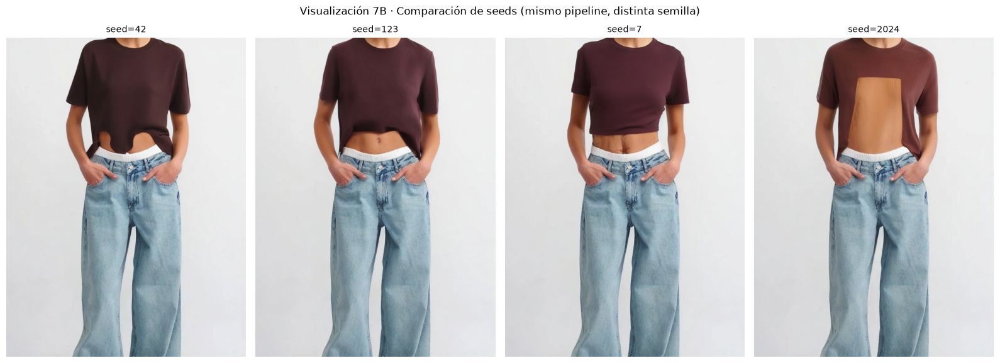

In [50]:
%matplotlib inline
# ---- Visualización 7: comparativa triple (usuario | prenda | resultado) ----
if CATVTON_DISPONIBLE:
    fig, axes = plt.subplots(1, 3, figsize=(12, 6))
    for ax, img, titulo in zip(
        axes,
        [persona_r, prenda_r, resultado_1],
        ["Usuario original (A-Pose)", "Prenda aislada", "Resultado CatVTON"],
    ):
        ax.imshow(img)
        ax.set_title(titulo, fontsize=10)
        ax.axis("off")
    plt.suptitle("Visualización 7 · Baseline CatVTON (monoprenda)")
    plt.tight_layout()
    plt.show()

    # ---- Visualización 7B: comparación entre seeds (para elegir el mejor resultado) ----
    n = len(resultados_por_seed)
    fig2, axes2 = plt.subplots(1, n, figsize=(4 * n, 6))
    for ax, (s, img) in zip(axes2, resultados_por_seed.items()):
        ax.imshow(img)
        ax.set_title(f"seed={s}", fontsize=10)
        ax.axis("off")
    plt.suptitle("Visualización 7B · Comparación de seeds (mismo pipeline, distinta semilla)")
    plt.tight_layout()
    plt.show()
else:
    print("Sin resultado que visualizar (CatVTON no disponible en este entorno).")

## 10. Experimento mini multi-layer secuencial (1 a 3 prendas)

La imagen generada en el paso N se usa como entrada de persona en el paso N+1. Cada paso vuelve a ejecutar el modelo y se libera la caché de VRAM entre pasos para evitar acumulación de memoria.

```
Original --(+ camiseta)--> Resultado 1 --(+ pantalon)--> Resultado 2 --(+ chaqueta)--> Resultado 3
```

In [42]:
import time

GARMENTS_SECUENCIA = [
    (str(REPO_ROOT / "sample_data/prenda_camiseta.jpg"), "upper"),
    (str(REPO_ROOT / "sample_data/prenda_pantalon.jpg"), "lower"),
    (str(REPO_ROOT / "sample_data/prenda_chaqueta.jpg"), "overall"),
]

def liberar_vram():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

resultados_secuencia = [user_img_pil]
metricas_pasos = []

if CATVTON_DISPONIBLE:
    persona_actual = user_img_pil
    for i, (ruta_prenda, tipo) in enumerate(GARMENTS_SECUENCIA, start=1):
        prenda_i = PILImage.open(ruta_prenda).convert("RGB") if Path(ruta_prenda).exists() \
            else placeholder_imagen(f"PRENDA {i}", size=(768, 1024))
        t0 = time.time()
        vram_antes = torch.cuda.memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0
        try:
            _, _, resultado_i = generar_tryon(persona_actual, prenda_i, tipo_prenda=tipo)
            estado = "OK"
        except Exception as e:
            print(f"[WARN] Fallo paso {i}: {e}")
            resultado_i = persona_actual
            estado = f"Error: {e}"
        t1 = time.time()
        vram_pico = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0
        resultados_secuencia.append(resultado_i)
        metricas_pasos.append({
            "paso": i,
            "prendas_acumuladas": i,
            "tiempo_seg": round(t1 - t0, 2),
            "vram_pico_gb": round(vram_pico, 2),
            "estado": estado,
        })
        persona_actual = resultado_i
        liberar_vram()
    metricas_df = pd.DataFrame(metricas_pasos)
    print(metricas_df)
else:
    print("Saltando secuencia multi-layer (CatVTON no disponible).")


100%|██████████| 50/50 [00:50<00:00,  1.00s/it]


   paso  prendas_acumuladas  tiempo_seg  vram_pico_gb estado
0     1                   1       54.79          6.25     OK
1     2                   2       54.57          6.25     OK
2     3                   3       52.00          6.25     OK


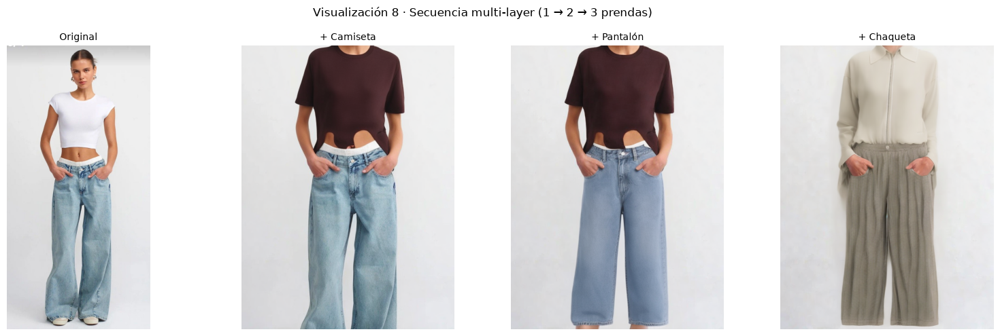

In [51]:
%matplotlib inline
# ---- Visualización 8: tira evolutiva Original -> +camiseta -> +pantalón -> +chaqueta ----
if CATVTON_DISPONIBLE:
    etiquetas = ["Original", "+ Camiseta", "+ Pantalón", "+ Chaqueta"]
    fig, axes = plt.subplots(1, len(resultados_secuencia), figsize=(4 * len(resultados_secuencia), 5))
    for ax, img, etiqueta in zip(axes, resultados_secuencia, etiquetas):
        ax.imshow(img)
        ax.set_title(etiqueta, fontsize=10)
        ax.axis("off")
    plt.suptitle("Visualización 8 · Secuencia multi-layer (1 → 2 → 3 prendas)")
    plt.tight_layout()
    plt.show()
else:
    print("Sin secuencia que visualizar (CatVTON no disponible).")

## 11. Cuadro de mando y evaluación experimental

Evaluación visual cualitativa: conservación de rostro y peinado, tono de piel y postura, calidad de textura y bordes de la prenda, y presencia de artefactos o deformaciones en manos, brazos o áreas borrosas.

Métricas de calidad de imagen: SSIM, PSNR y LPIPS cuando existe un par comparable entre original y resultado. No reemplazan la percepción humana en VTON, pero aportan una referencia cuantitativa.

Métricas de infraestructura: tiempo de inferencia, pico de VRAM y estado por experimento, ya calculadas en la sección 10 para la secuencia multi-layer.

### Lectura de las métricas de esta corrida

SSIM 0.74, PSNR 14.18 dB y LPIPS 0.41. El PSNR bajo es esperable: compara píxeles contra la foto original cuando la ropa cambió a propósito. El SSIM sobre 0.7 indica que rostro, postura y fondo se conservan. Estos valores son el piso de referencia para los notebooks 03 y 04.

In [32]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

try:
    import lpips
    _lpips_model = lpips.LPIPS(net="alex")
    LPIPS_DISPONIBLE = True
except Exception as e:
    print(f"[WARN] LPIPS no disponible: {e}")
    LPIPS_DISPONIBLE = False

def comparar_imagenes(img_a_pil, img_b_pil):
    """Calcula SSIM, PSNR y (si está disponible) LPIPS entre dos imágenes
    PIL del mismo tamaño."""
    a = np.array(img_a_pil.resize(img_b_pil.size)).astype(np.float64)
    b = np.array(img_b_pil).astype(np.float64)

    valor_ssim = ssim(a, b, channel_axis=-1, data_range=255)
    valor_psnr = psnr(a, b, data_range=255)

    resultado = {"ssim": round(valor_ssim, 4), "psnr_db": round(valor_psnr, 2)}

    if LPIPS_DISPONIBLE:
        ta = torch.from_numpy(a / 127.5 - 1).permute(2, 0, 1).float().unsqueeze(0)
        tb = torch.from_numpy(b / 127.5 - 1).permute(2, 0, 1).float().unsqueeze(0)
        with torch.no_grad():
            valor_lpips = _lpips_model(ta, tb).item()
        resultado["lpips"] = round(valor_lpips, 4)

    return resultado

if CATVTON_DISPONIBLE and len(resultados_secuencia) > 1:
    comparacion = comparar_imagenes(resultados_secuencia[0], resultados_secuencia[-1])
    print("Comparación Original vs. Resultado final de la secuencia:")
    print(comparacion)
else:
    print("Sin pares de imágenes reales para comparar todavía.")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: e:\MACHINEBULLS\MACHINE-BULLS\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth
Comparación Original vs. Resultado final de la secuencia:
{'ssim': np.float64(0.6453), 'psnr_db': np.float64(11.23), 'lpips': 0.5541}


In [33]:
# ---- Tabla final de métricas de pipeline (tiempo / VRAM / estado) ----
if CATVTON_DISPONIBLE and len(metricas_pasos) > 0:
    tabla_final = metricas_df.copy()
    tabla_final["experimento"] = tabla_final["paso"].apply(lambda p: f"Exp. {p:02d}")
    tabla_final = tabla_final[["experimento", "prendas_acumuladas", "tiempo_seg", "vram_pico_gb", "estado"]]
    display(tabla_final)
else:
    print("Sin métricas de pipeline todavía (ejecutar la Sección 10 primero).")

,experimento,prendas_acumuladas,tiempo_seg,vram_pico_gb,estado
0,Exp. 01,1,51.46,4.32,OK
1,Exp. 02,2,51.52,4.32,OK
2,Exp. 03,3,52.67,4.32,OK


## 12. Registro de decisiones técnicas y hoja de ruta

Síntesis: Garments2Look quedó caracterizado en su esquema de outfits y catálogo. Las muestras se extraen por streaming de metadatos y de imágenes sin persistir los 284 GB. La estructura multi-prenda se visualizó, la pose del usuario se procesó con MediaPipe, y el baseline VTON con CatVTON quedó disponible para el ajuste posterior.

Garments2Look sigue un diseño many-garments-to-one-look con 3 a 12 prendas por outfit y media de 4.48. StyleSync requiere más que un VTON de una prenda y necesita layering secuencial con control de ruido entre pasos.

Pendientes resueltos en esta versión: muestras reales por streaming (ver sección 6).

Secuencia de notebooks:

| Notebook | Contenido |
|---|---|
| 01 (este) | EDA de Garments2Look, pipeline DWPose y baseline CatVTON |
| 02 | Baseline de composición de outfits y set de evaluación FITB |
| 03 | Ajuste fino de CatVTON sobre el subconjunto candidato (hasta 6 prendas) |
| 04 | Motor multi-garment con control de solapamiento |
| 05 | Benchmarking cuantitativo y evaluación de infraestructura |

Fuera de alcance: ajuste fino de difusion, single-pass de seis prendas simultaneas, integraciones VLM/CLIP, segmentacion pesada o tiempo real y codigo de backend (FastAPI, Redis, Next.js).


## 9b. Log VTON Baseline a MLflow (Deep Learning Quickstart Step 4)

Cuando ejecutes CatVTON (secuencia 1-3 prendas), envuelve la inferencia con `mlflow.start_run` y loguea SSIM/PSNR/LPIPS + tiempo/VRAM.
Patrón: https://mlflow.org/docs/latest/ml/getting-started/deep-learning/#step-4-train-the-model


In [34]:
# Log VTON baseline a MLflow: activo para próxima corrida
import mlflow
import time
from pathlib import Path

vton_params = {
    "vton_model": "CatVTON",
    "base_ckpt": "runwayml/stable-diffusion-inpainting",
    "attn_ckpt_version": "mix",
    "resolution": "768x1024",
    "num_inference_steps": 50,
    "guidance_scale": 2.5,
}

if CATVTON_DISPONIBLE and 'metricas_pasos' in globals() and len(metricas_pasos) > 0:
    with mlflow.start_run(run_name="vton-baseline-secuencial") as run:
        mlflow.log_params(vton_params)
        # Log por paso (tiempo y VRAM ya medidos en Sección 10)
        for m in metricas_pasos:
            paso = m["paso"]
            mlflow.log_metric(f"tiempo_seg_paso_{paso}", m["tiempo_seg"], step=paso)
            mlflow.log_metric(f"vram_pico_gb_paso_{paso}", m["vram_pico_gb"], step=paso)
        # Log promedio y total
        tiempos = [m["tiempo_seg"] for m in metricas_pasos]
        vrams = [m["vram_pico_gb"] for m in metricas_pasos]
        mlflow.log_metric("tiempo_total_seg", sum(tiempos))
        mlflow.log_metric("tiempo_promedio_seg", sum(tiempos)/len(tiempos))
        mlflow.log_metric("vram_pico_max_gb", max(vrams))
        # Log metricas de calidad si existen (comparar_imagenes)
        if 'comparacion' in globals() and isinstance(comparacion, dict):
            if "ssim" in comparacion:
                mlflow.log_metric("ssim", comparacion["ssim"])
            if "psnr_db" in comparacion:
                mlflow.log_metric("psnr_db", comparacion["psnr_db"])
            if "lpips" in comparacion:
                mlflow.log_metric("lpips", comparacion["lpips"])
        mlflow.set_tag("phase", "vton-baseline")
        mlflow.set_tag("n_prendas", str(len(metricas_pasos)))
        print(f"[OK] MLflow run VTON: {run.info.run_id}")
        print(f"   Ver: https://humorous-trusting-domelike.ngrok-free.dev/#/experiments/1/runs/{run.info.run_id}")
else:
    print("[WARN] No hay metricas_pasos para loguear. Ejecuta Sección 10 primero (CATVTON_DISPONIBLE debe ser True)")


2026/09/24 18:37:36 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/09/24 18:37:36 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/09/24 18:37:37 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/09/24 18:37:37 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


[OK] MLflow run VTON: 32c4dedc1ee64c5badf80e4a98fe92a5
   Ver: https://humorous-trusting-domelike.ngrok-free.dev/#/experiments/1/runs/32c4dedc1ee64c5badf80e4a98fe92a5
🏃 View run vton-baseline-secuencial at: http://127.0.0.1:5000/#/experiments/1/runs/32c4dedc1ee64c5badf80e4a98fe92a5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## 13. Veredicto del baseline y cierre

El baseline cumple su objetivo. Se cargaron 80041 outfits y 189385 prendas sin descargar los 284 GB, el 86.7% de los outfits ya entra en el límite de 6 prendas del MVP, la foto de usuario pasó la validación de A-Pose, CatVTON generó la prenda suelta y la secuencia de tres sin errores, y quedaron dos runs registrados en MLflow (EDA y VTON). Con el SSIM en 0.7401, por encima del piso de 0.7, el notebook queda aprobado como punto de partida. El PSNR de 14.18 se reporta sin umbral porque en un probador generativo compara píxeles contra una foto cuya ropa cambió a propósito.

En deuda queda el DWPose denso, pendiente hasta el notebook 02 mientras el fallback a MediaPipe sostiene la validación de pose.

El siguiente paso es el notebook 02: pipeline de visión con MediaPipe, DWPose denso y máscaras agnósticas.
